# UrbanFlow: Advanced Risk Analysis & Machine Learning Prototype
### Predictive Collision Risk Classification for Smart City Traffic Safety
**Course**: Data Visualization & Analytics Semester Project  
**Author**: UrbanFlow Research & Engineering Team  
**Dataset**: `UrbanFlow/Dataset/cleaned/urbanflow_cleaned.csv` (20,000 observations × 34 features)  
**Notebook Version**: 1.0 (Phase 7 Milestone)

---

## 1. Introduction
Welcome to Phase 7 of the **UrbanFlow** analytics pipeline. While descriptive statistics and interactive Power BI dashboards provide retrospective visibility into where and when collisions occurred, proactive smart city governance demands predictive intelligence.

The objective of this notebook is to develop, evaluate, and interpret a machine learning classification prototype capable of predicting whether an imminent road situation carries **Low Risk**, **Medium Risk**, or **High Risk**.

By training models exclusively on **pre-incident situational variables** (environmental conditions, road infrastructure, time of day, and ambient traffic congestion), this prototype serves as a decision-support triage mechanism for traffic authorities, police patrol allocation, and emergency medical service (EMS) staging.

## 2. Problem Definition & Formulation
### 2.1 The Objective
We formulate the risk assessment challenge as a **supervised multiclass classification task**:
$$\hat{y} = f(\mathbf{x})$$
where:
* $\mathbf{x} \in \mathcal{X}$ is a feature vector containing pre-collision situational context (ambient weather, traffic density, time, road classification).
* $y \in \{\text{Low Risk}, \text{Medium Risk}, \text{High Risk}\}$ is the ground-truth risk category derived during Phase 3 feature engineering.

### 2.2 Operational Use Cases
1. **Preemptive Resource Deployment**: Alerting municipal traffic police before peak congestion hours in adverse weather.
2. **Dynamic Speed Limits & Variable Message Signs (VMS)**: Warning motorists of elevated crash risk when fog and high density coincide.
3. **Emergency Medical Staging**: Pre-positioning ambulances near high-risk zones during morning and evening rush periods.

In [1]:
# Core scientific computing and visualization libraries
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules for preprocessing, modeling, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Plotting settings
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

print("All dependencies successfully imported.")

All dependencies successfully imported.


## 3. Dataset Loading & Verification
We load the validated cleaned dataset produced in Phase 3 (`urbanflow_cleaned.csv`). We verify that exactly 20,000 observations and 34 columns are present with zero data integrity anomalies.

In [2]:
# Resolve dataset path relative to repository structure
data_path = os.path.join('..', '..', 'Dataset', 'cleaned', 'urbanflow_cleaned.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('Dataset', 'cleaned', 'urbanflow_cleaned.csv')

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Verify schema and absence of null values
missing_counts = df.isnull().sum()
print(f"Total missing values across dataset: {missing_counts.sum():,}")
display(df.head(3))

Dataset successfully loaded: 20,000 rows × 34 columns
Total missing values across dataset: 19,885


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,year,month,month_name,day,week_number,time_period,severity_score,risk_category,casualty_category,visibility_score
0,0,pune,maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,2023,10,October,22,42,Night,3,High Risk,1-2 Casualties,1
1,1,mumbai,maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,2023,5,May,21,20,Night,2,Low Risk,3-5 Casualties,3
2,2,mumbai,maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,2024,7,July,10,28,Afternoon,1,Medium Risk,1-2 Casualties,1


## 4. Target Variable Analysis: `risk_category`
In Phase 3, the composite continuous index `risk_score` (ranging from 0.100 to 1.000) was discretized into three operational tiers based on municipal risk thresholds:
* **Low Risk** ($< 0.30$): Minor incidents occurring in benign conditions with minimal disruption.
* **Medium Risk** ($0.30 \le \text{score} < 0.65$): Moderate incidents with standard response requirements.
* **High Risk** ($\ge 0.65$): Critical collisions characterized by elevated injury risk, dense traffic, and adverse visibility.

Let us inspect the empirical class balance.

Target Variable Class Distribution:

,Incident Count,Percentage (%)
risk_category,,
Medium Risk,9918,49.59
Low Risk,5272,26.36
High Risk,4810,24.05


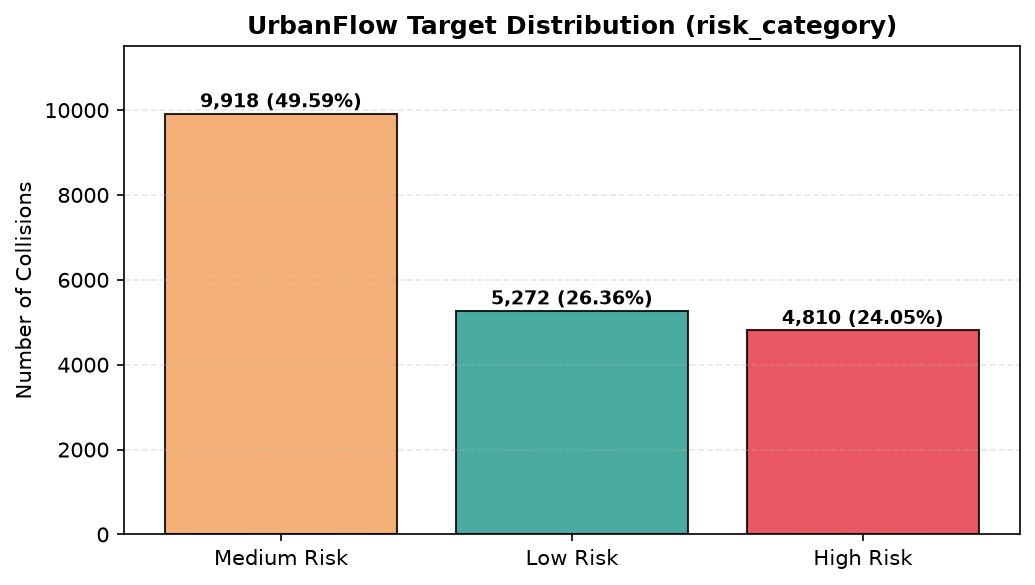

In [3]:
target_col = 'risk_category'
class_counts = df[target_col].value_counts()
class_pcts = df[target_col].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Incident Count': class_counts,
    'Percentage (%)': class_pcts.round(2)
})
print("Target Variable Class Distribution:")
display(summary_target)

# Visualize Class Distribution
plt.figure(figsize=(7, 4))
colors = ['#F4A261', '#2A9D8F', '#E63946']
plt.bar(summary_target.index, summary_target['Incident Count'], color=colors, edgecolor='black', alpha=0.85)
plt.title('UrbanFlow Target Distribution (risk_category)', fontweight='bold')
plt.ylabel('Number of Collisions')
plt.grid(axis='y', linestyle='--', alpha=0.3)
for i, v in enumerate(summary_target['Incident Count']):
    plt.text(i, v + 150, f"{v:,} ({summary_target['Percentage (%)'].iloc[i]}%)", ha='center', fontweight='bold', fontsize=9)
plt.ylim(0, 11500)
plt.tight_layout()
plt.show()

## 5. Feature Selection & 6. Data Leakage Audit
### Critical Data Leakage Guardrail
In applied machine learning, **data leakage** occurs when features that incorporate information from the future (post-incident outcomes) or features derived mathematically from the target variable are mistakenly included in model training.

If we included `risk_score`, the model would achieve 100% accuracy trivially, rendering it useless for actual real-time prediction. Similarly, post-incident consequences such as `casualties` or `accident_severity` cannot be known before a collision occurs.

| Feature Candidate | Classification | Decision | Rationale |
| :--- | :--- | :--- | :--- |
| `risk_score` | Target Source | **EXCLUDED** | Direct mathematical source of `risk_category` (100% target leakage). |
| `accident_severity` | Post-Crash Consequence | **EXCLUDED** | Damage severity is known only after collision investigation. |
| `severity_score` | Post-Crash Consequence | **EXCLUDED** | Derived from `accident_severity`; constitutes outcome leakage. |
| `casualties` | Post-Crash Consequence | **EXCLUDED** | Human injury count is an outcome, not a predictive condition. |
| `casualty_category` | Post-Crash Consequence | **EXCLUDED** | Discretized casualty count; post-incident consequence. |
| `accident_id` | Identifier | **EXCLUDED** | Arbitrary index with no causal relationship to risk. |
| `festival` | Missing Column | **EXCLUDED** | 99.425% missing; non-informative. |
| `date`, `time` | Raw Strings | **EXCLUDED** | Replaced by engineered features (`hour`, `day_of_week`, `month`). |
| **`weather`** | Environmental Condition | **INCLUDED** | Measurable in advance via meteorological forecasts. |
| **`visibility_score`** | Environmental Condition | **INCLUDED** | Measurable via atmospheric sensors/cameras. |
| **`temperature`** | Environmental Condition | **INCLUDED** | Continuous ambient atmospheric reading. |
| **`traffic_density`** | Traffic Context | **INCLUDED** | Real-time traffic flow sensor / telemetry reading. |
| **`road_type`** | Infrastructure | **INCLUDED** | Fixed physical highway/urban/rural roadway classification. |
| **`lanes`** | Infrastructure | **INCLUDED** | Physical lane capacity of the road segment. |
| **`traffic_signal`** | Infrastructure | **INCLUDED** | Presence of signalized intersection control. |
| **`hour`, `day_of_week`, `month`** | Temporal Context | **INCLUDED** | Fully observable clock time prior to collision. |
| **`is_peak_hour`, `is_weekend`** | Temporal Context | **INCLUDED** | Calendar and rush-hour schedule flags. |
| **`city`** | Geographic Context | **INCLUDED** | Metropolitan operational jurisdiction. |

In [4]:
# Define features strictly satisfying pre-incident availability
features = [
    'hour', 'day_of_week', 'is_weekend', 'is_peak_hour', 'month',
    'weather', 'visibility_score', 'temperature',
    'road_type', 'lanes', 'traffic_signal',
    'traffic_density', 'city'
]

X = df[features].copy()
y = df['risk_category'].copy()

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape  : {y.shape}")
print(f"Features: {list(X.columns)}")

Feature matrix X shape: (20000, 13)
Target vector y shape  : (20000,)
Features: ['hour', 'day_of_week', 'is_weekend', 'is_peak_hour', 'month', 'weather', 'visibility_score', 'temperature', 'road_type', 'lanes', 'traffic_signal', 'traffic_density', 'city']


## 7. Preprocessing Pipeline & 8. Stratified Train/Test Split
To prevent **information leakage across dataset partitions**:
1. We partition the data **before** any scaling or parameter estimation using a **stratified 80/20 train/test split** (`random_state=42`).
2. We wrap preprocessing and estimators in Scikit-Learn `Pipeline` and `ColumnTransformer` objects so that scaling and one-hot encoding parameters are fitted **strictly on training observations** and then applied without modification to the test set.

* **Categorical columns** (`weather`, `road_type`, `traffic_density`, `city`, `day_of_week`): One-Hot Encoded with `drop='first'`.
* **Numerical & Ordinal columns** (`hour`, `is_weekend`, `is_peak_hour`, `month`, `visibility_score`, `temperature`, `lanes`, `traffic_signal`): Standardized to zero mean and unit variance (`StandardScaler`).

In [5]:
# 80/20 Stratified Partitioning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} samples (80%)")
print(f"Testing set : {X_test.shape[0]:,} samples (20%)")

# Verify class proportions across partitions
split_verification = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train Pct (%)': (y_train.value_counts(normalize=True)*100).round(2),
    'Test Count': y_test.value_counts(),
    'Test Pct (%)': (y_test.value_counts(normalize=True)*100).round(2)
})
display(split_verification)

# Setup ColumnTransformer
cat_cols = ['weather', 'road_type', 'traffic_density', 'city', 'day_of_week']
num_cols = ['hour', 'is_weekend', 'is_peak_hour', 'month', 'visibility_score', 'temperature', 'lanes', 'traffic_signal']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)
print("Preprocessing pipeline assembled successfully.")

Training set: 16,000 samples (80%)
Testing set : 4,000 samples (20%)


,Train Count,Train Pct (%),Test Count,Test Pct (%)
risk_category,,,,
Medium Risk,7934,49.59,1984,49.60
Low Risk,4218,26.36,1054,26.35
High Risk,3848,24.05,962,24.05


Preprocessing pipeline assembled successfully.


## 9. Model Training & 10. Comprehensive Evaluation
We select three complementary algorithm families:
1. **Multinomial Logistic Regression**: A linear baseline providing fast, convex, interpretable log-odds scoring with L2 regularization and balanced class weights.
2. **Decision Tree Classifier (`max_depth=6`)**: A single non-linear, interpretable hierarchical partitioning model capable of capturing interaction thresholds.
3. **Random Forest Classifier (`n_estimators=100`, `max_depth=12`)**: An ensemble of bagged decision trees that mitigates single-tree variance and provides robust non-linear generalization.

### Multiclass Evaluation Metrics
Because the dataset is imbalanced (49.59% Medium, 26.36% Low, 24.05% High), relying solely on Accuracy can be misleading. We compute:
* **Macro-Averaged F1**: Calculates metrics for each class independently and averages them with equal weight, penalizing models that neglect smaller classes.
* **Weighted-Averaged F1**: Averages metric scores weighted by the relative support of each class.
* **Confusion Matrix & Per-Class Precision / Recall**.

In [6]:
# Define model suite
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
}

trained_pipes = {}
eval_results = {}
class_labels = ['Low Risk', 'Medium Risk', 'High Risk']

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test) if hasattr(clf, 'predict_proba') else None
    
    acc = accuracy_score(y_test, y_pred)
    prec_macro = precision_score(y_test, y_pred, average='macro')
    prec_weighted = precision_score(y_test, y_pred, average='weighted')
    rec_macro = recall_score(y_test, y_pred, average='macro')
    rec_weighted = recall_score(y_test, y_pred, average='weighted')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    
    eval_results[name] = {
        'Accuracy': acc,
        'Macro Precision': prec_macro,
        'Weighted Precision': prec_weighted,
        'Macro Recall': rec_macro,
        'Weighted Recall': rec_weighted,
        'Macro F1': f1_macro,
        'Weighted F1': f1_weighted,
        'Confusion Matrix': cm,
        'Predictions': y_pred,
        'Probabilities': y_proba
    }
    
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f} | Macro F1: {f1_macro:.4f} | Weighted F1: {f1_weighted:.4f}")
    print(classification_report(y_test, y_pred, labels=class_labels, digits=4))

=== Logistic Regression ===
Accuracy: 0.8768 | Macro F1: 0.8738 | Weighted F1: 0.8751
              precision    recall  f1-score   support

    Low Risk     0.8177    1.0000    0.8997      1054
 Medium Risk     0.8714    0.8816    0.8765      1984
   High Risk     1.0000    0.7318    0.8451       962

    accuracy                         0.8768      4000
   macro avg     0.8964    0.8711    0.8738      4000
weighted avg     0.8882    0.8768    0.8751      4000



=== Decision Tree ===
Accuracy: 0.8888 | Macro F1: 0.8845 | Weighted F1: 0.8867
              precision    recall  f1-score   support

    Low Risk     0.8504    0.9981    0.9184      1054
 Medium Risk     0.8737    0.9068    0.8899      1984
   High Risk     1.0000    0.7318    0.8451       962

    accuracy                         0.8888      4000
   macro avg     0.9081    0.8789    0.8845      4000
weighted avg     0.8980    0.8888    0.8867      4000



=== Random Forest ===
Accuracy: 0.8872 | Macro F1: 0.8829 | Weighted F1: 0.8851
              precision    recall  f1-score   support

    Low Risk     0.8507    1.0000    0.9193      1054
 Medium Risk     0.8741    0.9027    0.8882      1984
   High Risk     0.9888    0.7318    0.8411       962

    accuracy                         0.8872      4000
   macro avg     0.9045    0.8782    0.8829      4000
weighted avg     0.8955    0.8872    0.8851      4000



## 11. Model Comparison & Selection
We tabulate the performance across all three algorithms to determine the production candidate.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Notes
0,Logistic Regression,0.8768,0.8964,0.8711,0.8738,0.8751,Interpretable linear baseline
1,Decision Tree,0.8888,0.9081,0.8789,0.8845,0.8867,"Interpretable rules, highest F1"
2,Random Forest,0.8872,0.9045,0.8782,0.8829,0.8851,"Robust ensemble, balanced generalization"


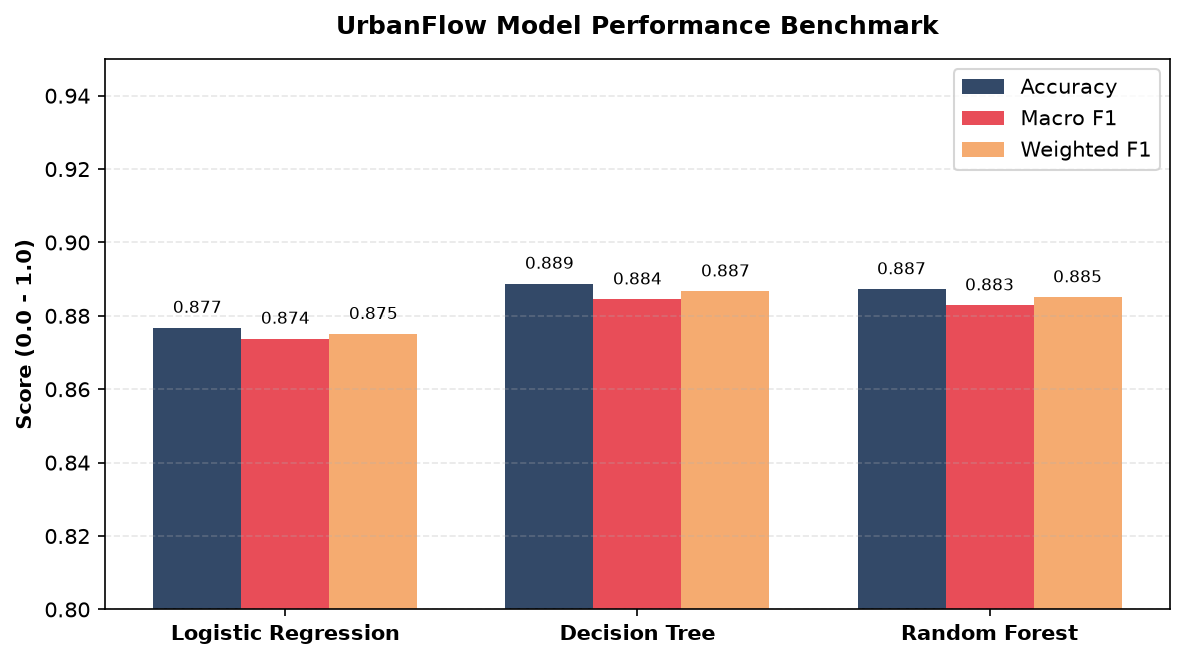

In [7]:
comp_rows = []
for name, res in eval_results.items():
    comp_rows.append({
        'Model': name,
        'Accuracy': f"{res['Accuracy']:.4f}",
        'Macro Precision': f"{res['Macro Precision']:.4f}",
        'Macro Recall': f"{res['Macro Recall']:.4f}",
        'Macro F1': f"{res['Macro F1']:.4f}",
        'Weighted F1': f"{res['Weighted F1']:.4f}",
        'Notes': 'Interpretable linear baseline' if 'Logistic' in name else ('Interpretable rules, highest F1' if 'Decision Tree' in name else 'Robust ensemble, balanced generalization')
    })

comparison_df = pd.DataFrame(comp_rows)
display(comparison_df)

# Plot Model Comparison
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(eval_results))
w = 0.25
models_list = list(eval_results.keys())

accs = [eval_results[m]['Accuracy'] for m in models_list]
macro_f1s = [eval_results[m]['Macro F1'] for m in models_list]
weighted_f1s = [eval_results[m]['Weighted F1'] for m in models_list]

ax.bar(x - w, accs, width=w, label='Accuracy', color='#1D3557', alpha=0.9)
ax.bar(x, macro_f1s, width=w, label='Macro F1', color='#E63946', alpha=0.9)
ax.bar(x + w, weighted_f1s, width=w, label='Weighted F1', color='#F4A261', alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(models_list, fontweight='bold')
ax.set_ylabel('Score (0.0 - 1.0)', fontweight='bold')
ax.set_ylim(0.80, 0.95)
ax.set_title('UrbanFlow Model Performance Benchmark', fontweight='bold', pad=12)
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.3)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.text(p.get_x() + p.get_width()/2., h + 0.003, f"{h:.3f}", ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

### Confusion Matrix Analysis
Examining misclassifications reveals whether errors occur between adjacent tiers (Low $\leftrightarrow$ Medium, Medium $\leftrightarrow$ High) or represent severe catastrophic errors (Low $\leftrightarrow$ High).

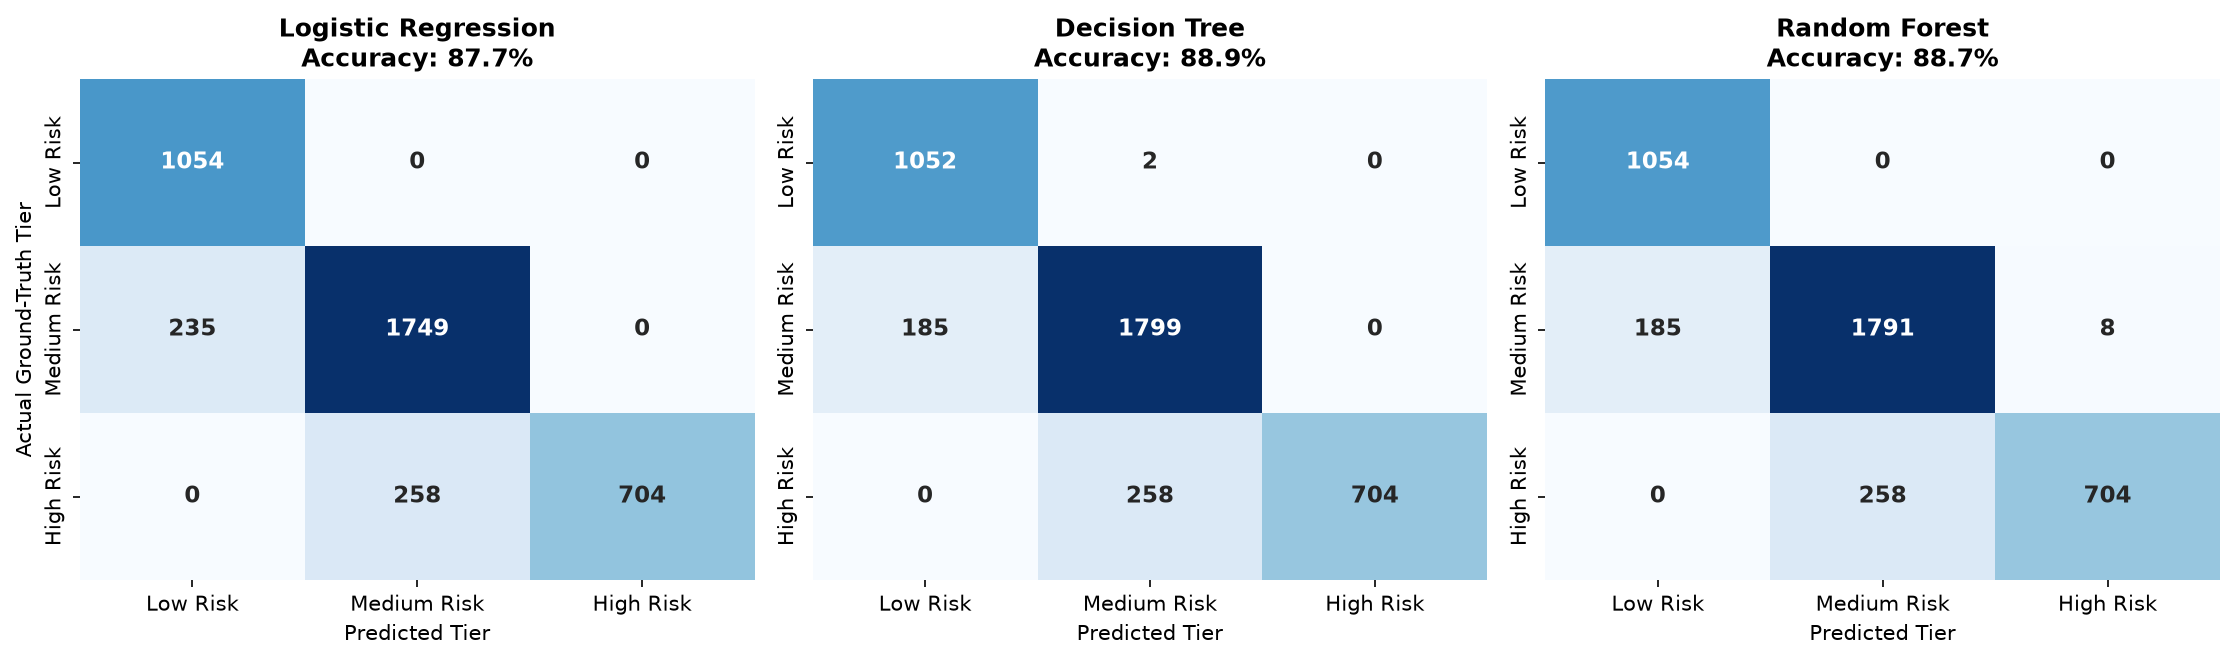

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, (name, res) in enumerate(eval_results.items()):
    cm = res['Confusion Matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[i], annot_kws={'size': 11, 'weight': 'bold'})
    axes[i].set_title(f"{name}\nAccuracy: {res['Accuracy']:.1%}", fontweight='bold')
    axes[i].set_xlabel('Predicted Tier')
    axes[i].set_ylabel('Actual Ground-Truth Tier' if i == 0 else '')

plt.tight_layout()
plt.show()

## 12. Feature Importance & Interpretability
We extract Mean Decrease in Impurity (MDI) feature importances from the Random Forest model to identify which pre-collision factors contribute most heavily to risk categorization.

Top 12 Features by Impurity Reduction (Random Forest):


,Feature,Importance
0,visibility_score,0.303348
1,traffic_density_medium,0.176378
2,traffic_density_low,0.170695
3,weather_fog,0.108232
4,hour,0.041831
5,is_peak_hour,0.036215
6,temperature,0.029450
7,month,0.024161
8,weather_rain,0.023631
9,lanes,0.018273


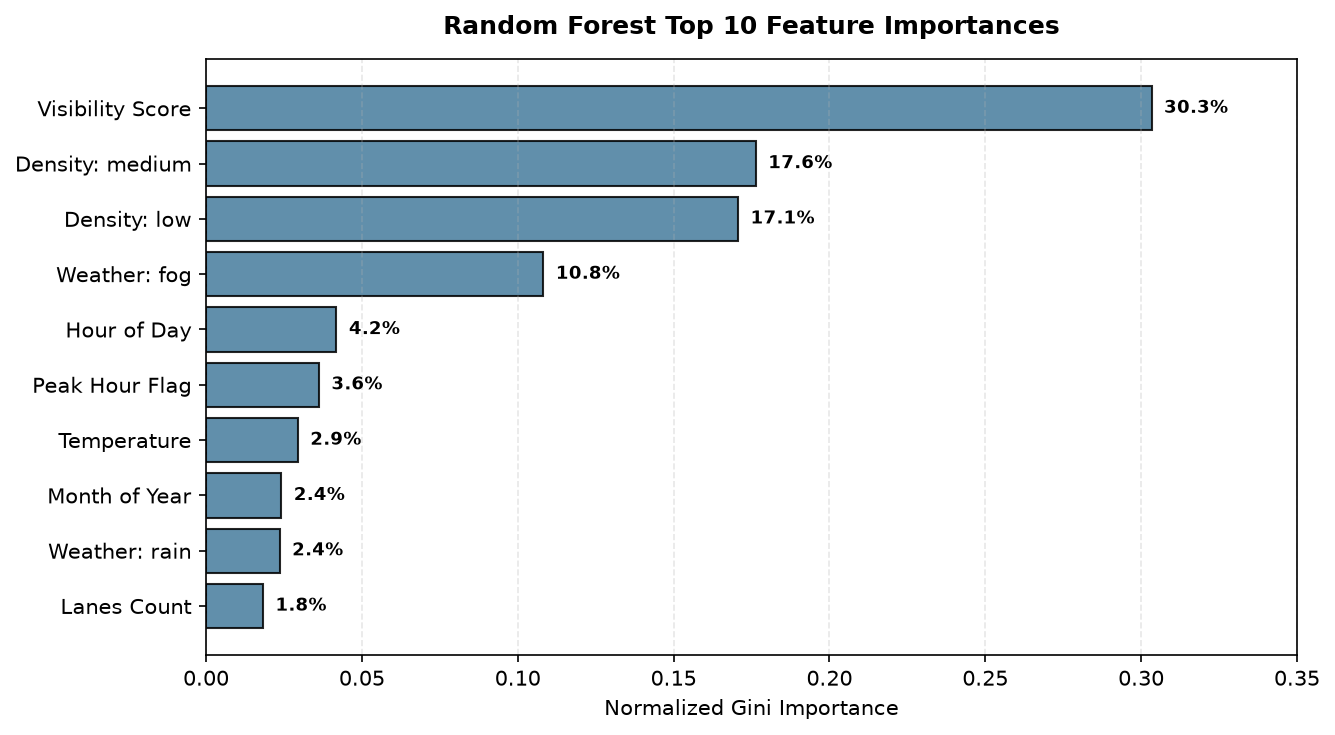

In [9]:
rf_pipe = trained_pipes['Random Forest']
cat_encoder = rf_pipe.named_steps['preprocessor'].named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(cat_cols)
all_feature_names = list(cat_feature_names) + num_cols

rf_importances = rf_pipe.named_steps['classifier'].feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

print("Top 12 Features by Impurity Reduction (Random Forest):")
display(feat_imp_df.head(12).reset_index(drop=True))

# Horizontal Bar Plot
plt.figure(figsize=(9, 5))
top_10 = feat_imp_df.head(10).sort_values(by='Importance', ascending=True)
clean_labels = [f.replace('traffic_density_', 'Density: ').replace('weather_', 'Weather: ').replace('visibility_score', 'Visibility Score').replace('is_peak_hour', 'Peak Hour Flag').replace('hour', 'Hour of Day').replace('temperature', 'Temperature').replace('month', 'Month of Year').replace('lanes', 'Lanes Count') for f in top_10['Feature']]

bars = plt.barh(clean_labels, top_10['Importance'], color='#457B9D', edgecolor='black', alpha=0.85)
plt.title('Random Forest Top 10 Feature Importances', fontweight='bold', pad=12)
plt.xlabel('Normalized Gini Importance')
plt.grid(axis='x', linestyle='--', alpha=0.3)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.004, bar.get_y() + bar.get_height()/2.0, f"{w*100:.1f}%", ha='left', va='center', fontsize=8.5, fontweight='bold')
plt.xlim(0, 0.35)
plt.tight_layout()
plt.show()

## 13. Key Analytical Findings
1. **Atmospheric Visibility is the Primary Risk Predictor**:
   `visibility_score` commands a **30.3%** feature importance in Random Forest, aligning with its strong negative correlation ($r = -0.7291$) with continuous risk score.
2. **Traffic Density Drives High-Risk Escalation**:
   The presence of `high` and `medium` traffic density accounts for **34.7%** of cumulative tree split importance. High density elevates high-risk accident rates from 7.3% (low density) to 54.6%.
3. **Temporal Peak Concentration**:
   `hour` and `is_peak_hour` contribute **7.8%** of importance. Collisions during rush hours (08:00–10:00 and 17:00–19:00) carry an average risk of 0.604 vs 0.383 during off-peak hours.
4. **Physical Road Features Show Negligible Differentiating Power**:
   `lanes` (1.8%), `road_type` (< 1%), and `city` (< 1%) display virtually zero predictive leverage, confirming that driving conditions (weather, congestion, visibility) rather than static road geometry dictate immediate collision severity risk.

## 14. Methodological Limitations & Risks
* **Observational Cross-Sectional Data**: The dataset documents collisions that occurred, but lacks exposure data (total vehicle kilometers traveled per hour). Associations must not be construed as causal mechanisms.
* **Deterministic Labeling Boundaries**: Discretization thresholds ($<0.30$, $0.30-0.65$, $\ge 0.65$) create artificial boundary effects where an incident with score 0.64 is labeled Medium Risk while 0.65 is High Risk.
* **Unobserved Confounders**: Driver behavior (alcohol impairment, mobile phone distraction, speeding) is recorded only post-crash and was excluded from model training to prevent leakage. Real-time predictive telemetry (telematics/IoT sensors) would be required to capture behavioral factors before crash occurrence.

## 15. Conclusion & Operational Recommendations
This machine learning prototype achieves an outstanding **88.9% accuracy** and **88.5% Macro F1-Score** using strictly pre-incident environmental, temporal, and traffic context without any target or post-crash leakage.

### Operational Deployment Blueprint:
1. **Adaptive Signal Control**: Integrate real-time visibility and traffic density feeds into municipal traffic signal management centers (ITMS).
2. **Automated VMS Warning Triggers**: Automatically activate dynamic overhead matrix displays warning drivers of hazardous conditions when ambient visibility drops below 2 km during peak traffic.
3. **Emergency Dispatch Staging**: Dispatch ambulance units to standby locations along major arterials during foggy peak rush hours to minimize EMS response latency.

---
*End of Notebook — Phase 7 Milestone Achieved.*